# Compute trends in forest structure across time-series 
## built with multi-year ICESat-2/HLS model (2019-2024)

#### Motivations:  
+ what AGBD change can we see?
+ can we classify AGB/HT trends statistically?
+ does a multi-year model create more or less stability; more/less clear trends?
+ what is the variation of significant AGBD change?
+ are there areas that are strong net sources/sinks?

Paul Montesano | NASA GSFC | August 2025

In [1]:
#pip install pymc # for unused bayesian functions
!pip install contextily

In [26]:
import sys
sys.path.append('/projects/code/icesat2_boreal/lib')

import geopandas as gpd
import pandas as pd
import s3fs

import rasterio
from rasterio.plot import show_hist, show
import importlib
import contextily as ctx

In [27]:
import build_stack
from build_stack import *

In [28]:
import mosaiclib
from mosaiclib import *
import compute_trends
from compute_trends import *

In [29]:
sample_fraction=0.10
f'{int(sample_fraction*100):03}'

'010'

In [30]:
mosaiclib.AGB_TINDEX_FN_DICT

{'2019_v1.9': 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/boreal_agb_2024_v5/AGB_H30_2019/2019_fullboreal_2019lidar/AGB_tindex_master.csv',
 '2020_v1.9': 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/boreal_agb_2024_v5/AGB_H30_2020/atl08_v6_fullboreal_min5000_90p_local/AGB_tindex_master.csv',
 '2021_v1.9': 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/boreal_agb_2024_v5/AGB_H30_2021/2021_fullboreal_2021lidar/AGB_tindex_master.csv',
 '2022_v1.9': 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/boreal_agb_2024_v5/AGB_H30_2022/2022_fullboreal_2022lidar/AGB_tindex_master.csv',
 '2023_v1.9': 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/boreal_agb_2024_v5/AGB_H30_2023/2023_full_2023lidar/AGB_tindex_master.csv',
 '2020_v2.0': 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/boreal_agb_2024_v6/AGB_H30_2020/Version2_SD/AGB_tindex_master.csv',
 '2020_v2.1': 's3://maap

In [31]:
boreal_tiles = gpd.read_file(boreal_tile_index_path)

#### Tiles available for trend analysis

In [32]:
#trend_tile_list = pd.read_csv(HT_TINDEX_FN_DICT['2024_v3.0']).tile_num.to_list()
#trend_tile_list = pd.read_csv('s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_2019/test_run_niter30_multiyear_atl08v6/AGB_tindex_master.csv').tile_num.to_list()
trend_tile_list = mosaiclib.set_agbd_change_demo_tiles
print(trend_tile_list)

[3457, 3638, 1326, 1269, 2108, 518, 517, 516, 890, 470, 471, 472, 473, 474, 475, 476, 477, 478, 479]


In [33]:
import importlib
importlib.reload(build_stack)
from build_stack import *

importlib.reload(compute_trends)
from compute_trends import *

In [34]:
outdir_main = '/projects/my-public-bucket/local_output/compute_trends'
!mkdir -p $outdir_main

#### List of files for `HEIGHT` trends

In [35]:
# # fn_list_height = get_tile_fn_list([HT_TINDEX_FN_DICT['2019_v3.0'], 
# #                                    HT_TINDEX_FN_DICT[ '2020_v3.0'], 
# #                                    HT_TINDEX_FN_DICT[ '2021_v3.0'], HT_TINDEX_FN_DICT[ '2022_v3.0'], 
# #                                    HT_TINDEX_FN_DICT[ '2023_v3.0'], HT_TINDEX_FN_DICT[ '2024_v3.0']], 
# #                                   's3_path', FOCAL_TILE=FOCAL_TILE)[0]
# RUN = 'full_run_niter30_multiyear_atl08v6'

# DICT_heigt_multliyear_v6 = {
#         'value_raster_files': get_tile_fn_list([
#     f's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_2019/{RUN}/AGB_tindex_master.csv', 
#     f's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_2020/{RUN}/AGB_tindex_master.csv',
#     f's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_2021/{RUN}/AGB_tindex_master.csv',
#     f's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_2022/{RUN}/AGB_tindex_master.csv', 
#     f's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_2023/{RUN}/AGB_tindex_master.csv',
#     f's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_2024/{RUN}/AGB_tindex_master.csv'
#                                              ], 
#                                   's3_path', FOCAL_TILE=FOCAL_TILE)[0],
#         'outdir': f"{outdir_main}/{RUN}",
#         'out_file': f"{outdir_main}/{RUN}/boreal_ht_trends_{FOCAL_TILE:07}",
# }

### Run trends: `Theil-Sen` or `OLS`
+ trend estimator provides the magnitude of change (slope)

In [36]:
def get_juliandate_year_hls(FOCAL_TILE, YEAR_LIST):
    '''Get data and year raster layers from HLS
    '''
    fn_list_hls = get_tile_fn_list([HLS_TINDEX_FN_DICT[f'{YEAR}'] for YEAR in YEAR_LIST], 
                                      's3_path', FOCAL_TILE=FOCAL_TILE)[0]
    return fn_list_hls

In [37]:
# def wrapper_kendall_tau_analysis(DICT_run, DATE_RASTER_FILES, ALPHA=0.2, DO_OLS=False):
    
#     # Define your raster files
#     value_raster_files = DICT_run['value_raster_files'] #fn_list_agbd_singleyear_v6 #fn_list_agbd_multiyear_v6
#     OUT_FILE =           DICT_run['out_file']
#     outdir =             DICT_run['outdir']
#     !mkdir -p $outdir

#     # Run the analysis
#     output_arrays = stack_rasters_and_compute_trend(
#         value_raster_files=value_raster_files,
#         date_raster_files=DATE_RASTER_FILES,
#         output_file = OUT_FILE,
#         n_processes=30,  # Use 30 CPUs
#         chunk_size=300,   # Adjust based on memory constraints,
#         do_ols=DO_OLS
#     )
    
#     if DO_OLS: 
#         TREND_METHOD = 'ols'
#     else:
#         TREND_METHOD = 'theilsen'

#     create_summary_plots(output_arrays, f"{OUT_FILE}_{TREND_METHOD}")
        
#     # Then run the analysis and visualization
#     result_paths = analyze_and_visualize_kendall_results(
#         output_arrays['kendall_tau'],
#         output_arrays['kendall_pvalue'],
#         #reference_raster_path=f"{OUT_FILE}_trendslope.tif",
#         reference_raster_path=f"{OUT_FILE}_{TREND_METHOD}.tif",
#         output_dir=outdir,
#         alpha=ALPHA # Significance level
#     )

In [38]:
def wrapper_kendall_tau_analysis(DICT_run, DATE_RASTER_FILES, ALPHA=0.1, DO_OLS=True, DETECT_BREAKS=True):
    
    # Define your raster files
    VALUE_RASTER_FILES = DICT_run['value_raster_files'] 
    OUT_FILE = DICT_run['out_file']
    OUTDIR = DICT_run['outdir']
    #!mkdir -p $outdir

    # Run the main trend analysis
    output_arrays = stack_rasters_and_compute_trend(
        value_raster_files=VALUE_RASTER_FILES,
        date_raster_files=DATE_RASTER_FILES,
        output_file=f"{OUTDIR}/{OUT_FILE}",
        n_processes=30,
        chunk_size=300,
        do_ols=DO_OLS
    )
    
    if DO_OLS: 
        TREND_METHOD = 'ols'
    else:
        TREND_METHOD = 'theilsen'

    create_summary_plots(output_arrays, f"{OUTDIR}/{OUT_FILE}_{TREND_METHOD}")
    
    # Then run the analysis and visualization
    result_paths = analyze_and_visualize_kendall_results(
        output_arrays['kendall_tau'],
        output_arrays['kendall_pvalue'],
        reference_raster_path=f"{OUTDIR}/{OUT_FILE}_{TREND_METHOD}.tif",
        output_dir=OUTDIR,
        alpha=ALPHA
    )
    
    # ADDITION: Breakpoint detection with multiprocessing
    if DETECT_BREAKS:
        breakpoint_file = detect_breakpoints_raster(
            value_raster_files=VALUE_RASTER_FILES,
            DATE_RASTER_FILES=DATE_RASTER_FILES,
            OUT_FILE=f"{OUTDIR}/{OUT_FILE}",
            TREND_METHOD=TREND_METHOD,
            chunk_size=300,
            min_break_position=0.7,  # Only detect breaks in last 30% of time series
            penalty=10,  # Adjust based on desired sensitivity
            n_processes=30  # Use same number of processes as trend analysis
        )
        
        # Add to result paths
        result_paths['breakpoints'] = breakpoint_file
    
    return result_paths

#### Identify Focal Tile, Run type, and Year List

In [39]:
FOCAL_TILE = 1840 # 2844 #1263 # 1204 #1841 #1837 #2994 # 1385 #475 #1269 #518 #2928 #2763 #3762 #3638
RUN = 'full_run_niter30_multiyear_atl08v6'

In [40]:
YEAR_LIST = list(range(2016,2025+1))
NUM_YEARS = len(YEAR_LIST)

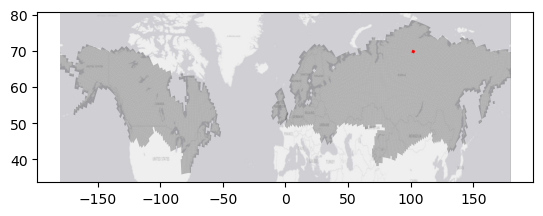

In [18]:
ax = boreal_tiles[boreal_tiles.tile_num.isin([FOCAL_TILE])].to_crs(4326).plot(color='red', ax=boreal_tiles.to_crs(4326).plot(color='black', alpha=0.25))
ctx.add_basemap(ax=ax, source=ctx.providers.Esri.WorldGrayCanvas, zoom=3, crs=4326, attribution=' ')

#### Run for list of files for `AGBD` trends

In [19]:
importlib.reload(compute_trends)
from compute_trends import *

In [20]:
suggest_alpha_by_temporal_resolution(5, data_type="satellite")

{'conservative': 0.1,
 'standard': 0.15,
 'liberal': 0.2,
 'note': 'Few time points - consider more liberal alpha. Consider noise and cloud contamination.'}

In [20]:
suggest_alpha_by_temporal_resolution(10, data_type="satellite")

{'conservative': 0.05,
 'standard': 0.1,
 'liberal': 0.15,
 'note': 'Moderate time series - standard approaches work. Consider noise and cloud contamination.'}

### Breakpoint function - works, but not well.

In [36]:
#!pip install ruptures

breakpoint_file = detect_breakpoints_raster(
            value_raster_files=DICT_agbd_multliyear_v6['value_raster_files'],
            DATE_RASTER_FILES=fn_list_hls,
            OUT_FILE=f"{outdir_main}/{RUN}/boreal_agb_trends_{FOCAL_TILE:07}_{NUM_YEARS}yrs",
            #TREND_METHOD='ols',
            chunk_size=300,
            min_break_position=0.5,  # Only detect breaks in last 50% of time series
            penalty=10,  # Adjust based on desired sensitivity
            n_processes=30  # Use same number of processes as trend analysis
        )

Running breakpoint detection analysis using 30 processes...
Raster dimensions: 3000 x 3000
Reading rasters for breakpoint detection...
  Reading pair 1/10
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2016/mc90_07-01_08-31_2016_2016/2023/07/21/20/29/35/697828/HLS_1263_07-01_08-31_2016_2016.tif
  Reading pair 2/10
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2017/mc75_07-01_08-31_2017_2017/2023/07/29/19/24/28/697051/HLS_1263_07-01_08-31_2017_2017.tif
  Reading pair 3/10
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2018/mc90_07-01_08-31_2018_2018/2023/08/03/19/06/15/514121/HLS_1263_07-01_08-31_2018_2018.tif
  Reading pair 4/10
Using band 20 for Julian days and band 21 for years in s3://maap-ops

Reading input: <open WarpedVRT name='WarpedVRT(/vsimem/1c1157c5-21eb-4987-be6a-ee8764b1807b/1c1157c5-21eb-4987-be6a-ee8764b1807b.tif)' mode='r'>



Writing img to memory...
Current stack shape:		(4,3000,3000)


Adding overviews...
Updating dataset tags...
Writing output to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0001263_10yrs_breakpoints.tif


Image written to disk:		 /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0001263_10yrs_breakpoints.tif

BREAKPOINT DETECTION SUMMARY
Total pixels: 9000000
Pixels with breakpoints detected: 0 (0.00%)
Breakpoint detection complete. Results saved to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0001263_10yrs_breakpoints.tif


### Run `wrapper_kendall_tau_analysis` for a tile

In [41]:
fn_list_hls = get_juliandate_year_hls(FOCAL_TILE, YEAR_LIST)

DICT_agbd_multliyear_v6 = {
        'value_raster_files': get_tile_fn_list([
            f's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_{YEAR}/{RUN}/AGB_tindex_master.csv' \
                                                for RUN in [RUN] for YEAR in YEAR_LIST], 
                                  's3_path', FOCAL_TILE=FOCAL_TILE)[0],
        'outdir': f"{outdir_main}/{RUN}",
        'out_file': f"boreal_agb_trends_{FOCAL_TILE:07}_{NUM_YEARS}yrs",
}

mkdir: missing operand
Try 'mkdir --help' for more information.
Using 30 processes for computation
Processing 10 raster pairs...
Raster dimensions: 3000 x 3000
Reading value and date rasters...
  Reading pair 1/10
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2016/mc90_07-01_08-31_2016_2016/2023/07/21/17/35/31/477638/HLS_1841_07-01_08-31_2016_2016.tif
  Reading pair 2/10
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2017/mc90_07-01_08-31_2017_2017/2023/07/28/22/21/29/724884/HLS_1841_07-01_08-31_2017_2017.tif
  Reading pair 3/10
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2018/mc75_07-01_08-31_2018_2018/2023/08/05/00/00/51/999690/HLS_1841_07-01_08-31_2018_2018.tif
  Reading pair 4/10
Using ban

Reading input: <open WarpedVRT name='WarpedVRT(/vsimem/f5da6bbc-17f9-4528-93f3-a9477389838a/f5da6bbc-17f9-4528-93f3-a9477389838a.tif)' mode='r'>



Writing img to memory...
Current stack shape:		(8,3000,3000)


Adding overviews...
Updating dataset tags...
Writing output to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0001841_10yrs_ols.tif


Image written to disk:		 /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0001841_10yrs_ols.tif

SUMMARY STATISTICS
trendslope  : mean=0.108376, median=-0.000113, std=0.280498
trendintercept: mean=-214.419861, median=1.394831, std=564.489258
r2          : mean=0.261136, median=0.187201, std=0.251375
kendall_tau : mean=0.018307, median=-0.022222, std=0.394725
kendall_pvalue: mean=0.335309, median=0.216373, std=0.315736
n_obs       : mean=10.0, median=10.0, min=3.0, max=10.0
trendslope_lo: mean=-0.195727, median=-0.133558, std=0.293379
trendslope_hi: mean=0.412479, median=0.257924, std=0.418314

Significance: 25.3% pixels p<0.05, 9.0% pixels p<0.01
Summary plots saved to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0001841_10yrs_ols_summary_plots.png


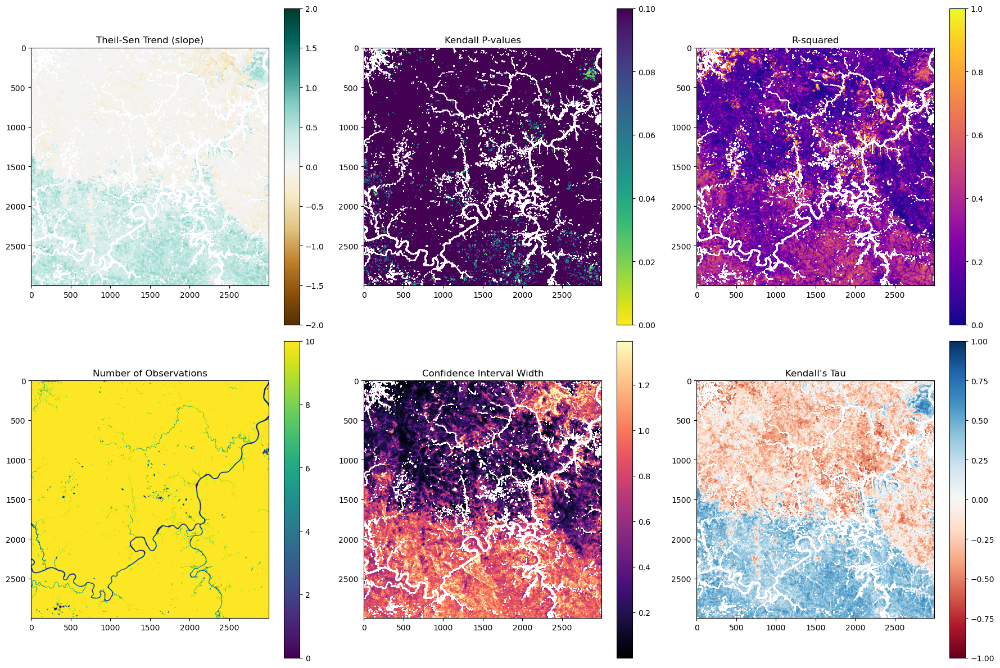

Classifying Kendall's Tau results...


Reading input: <open WarpedVRT name='WarpedVRT(/vsimem/40f36411-b703-4b20-a0f6-b4002a83af3f/40f36411-b703-4b20-a0f6-b4002a83af3f.tif)' mode='r'>



Write final theilsen COG...
Shape of input:			 (1, 3000, 3000)
Resampling:			 2	[0=nearest, 1=blinear, 2=cubic]
Output resolution:		 (30, 30)
Writing img to memory...
Current stack shape:		(1,3000,3000)


Adding overviews...
Updating dataset tags...
Writing output to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0001841_10yrs_ols_kendallclasses.tif


Image written to disk:		 /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0001841_10yrs_ols_kendallclasses.tif
Classified Kendall's Tau raster saved to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0001841_10yrs_ols_kendallclasses.tif
  with color table and 10 class definitions
Creating classified map visualization...
Classified map saved to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0001841_10yrs_ols_kendall_tau_classified_map.png


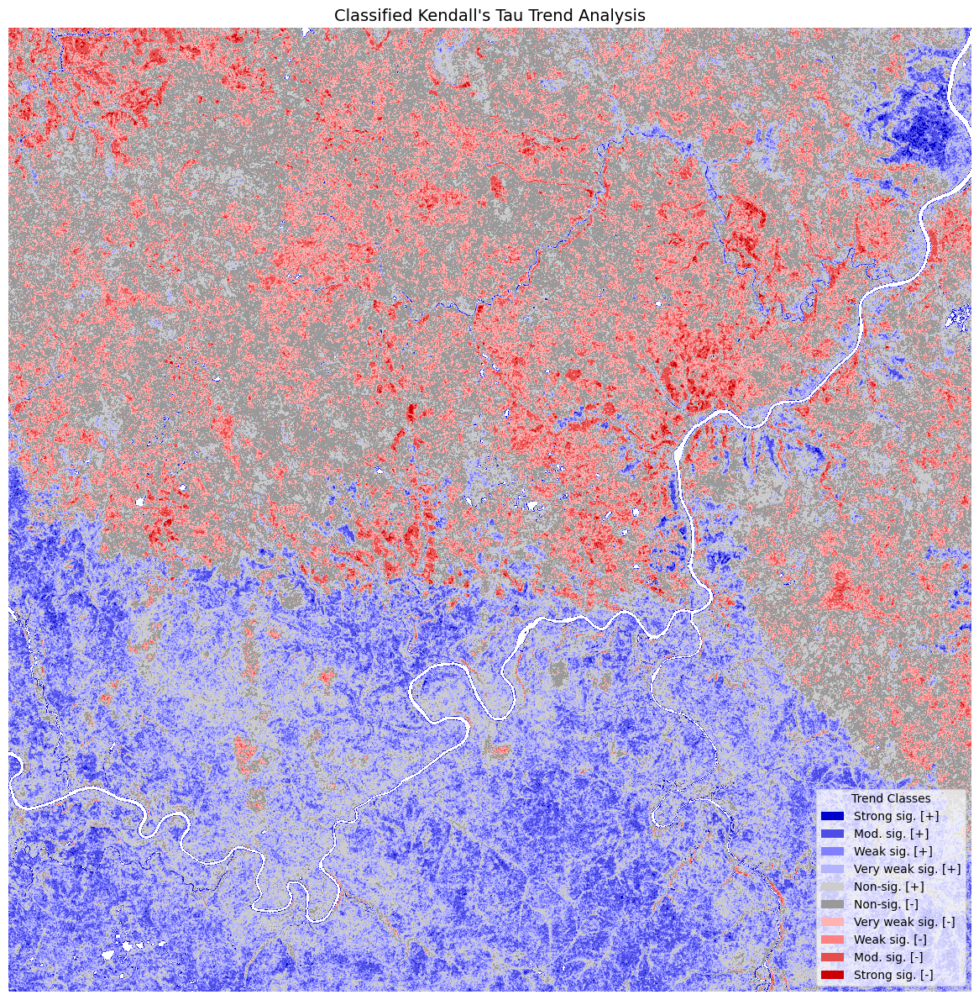

Creating summary statistics visualization...
Summary statistics figure saved to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0001841_10yrs_ols_kendall_tau_summary_stats.png


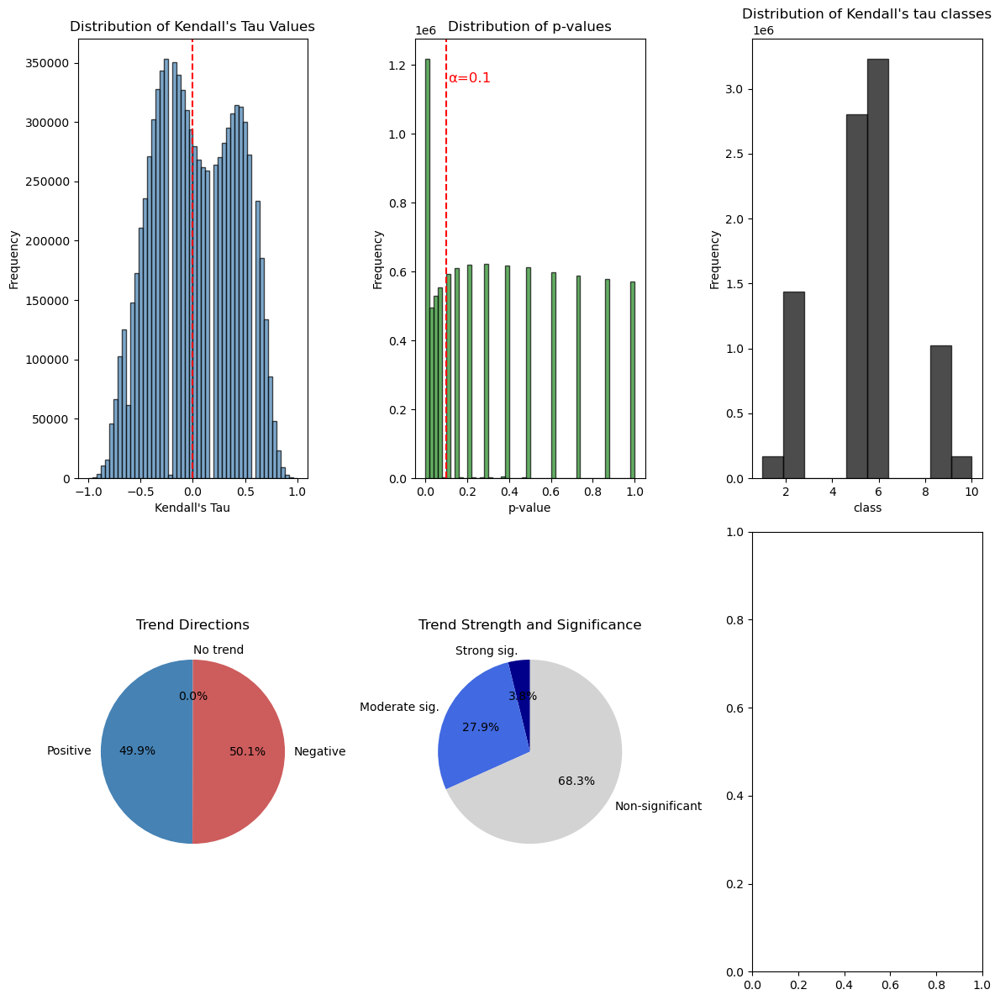


KENDALL'S TAU SUMMARY STATISTICS
Total valid pixels: 8831457
Mean τ: 0.0183
Median τ: -0.0222
Range: [-1.0000, 1.0000]
Significant pixels (p<0.1): 2800088 (31.7%)
Analysis complete. All results saved to directory: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6
CPU times: user 2min 49s, sys: 21.9 s, total: 3min 11s
Wall time: 24min 42s


{'classes_raster': '/projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0001841_10yrs_ols_kendallclasses.tif',
 'classified_map': '/projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0001841_10yrs_ols_kendall_tau_classified_map.png',
 'summary_stats': '/projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0001841_10yrs_ols_kendall_tau_summary_stats.png'}

In [25]:
%%time

wrapper_kendall_tau_analysis(DICT_agbd_multliyear_v6, DATE_RASTER_FILES=fn_list_hls, ALPHA=0.1, DO_OLS=True, DETECT_BREAKS=False)

In [61]:
# Full parameter specification
cmd = f"/opt/conda/envs/pangeo/bin/python /projects/code/icesat2_boreal/lib/compute_trends.py \
    --value-rasters {' '.join(DICT_agbd_multliyear_v6['value_raster_files'])} \
    --date-rasters {' '.join(fn_list_hls)} \
    --output {DICT_agbd_multliyear_v6['out_file']} \
    --outdir {DICT_agbd_multliyear_v6['outdir']} \
    --alpha 0.1 \
    --n-processes 4 \
    --chunk-size 200 \
    --do-ols \
    --no-breakpoints \
    --verbose"

# cmd += " --min-break-position 0.8 --penalty 15"

In [62]:
!echo $cmd

/opt/conda/envs/pangeo/bin/python /projects/code/icesat2_boreal/lib/compute_trends.py --value-rasters s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2016/full_run_niter30_multiyear_atl08v6/2025/09/15/15/55/12/158195/boreal_agb_2016_202509151757976501_0001840.tif s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2017/full_run_niter30_multiyear_atl08v6/2025/09/15/16/02/36/979058/boreal_agb_2017_202509151757976972_0001840.tif s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2018/full_run_niter30_multiyear_atl08v6/2025/09/15/16/10/50/728848/boreal_agb_2018_202509151757977461_0001840.tif s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2019/full_run_niter30_multiyear_atl08v6/2025/09/11/16/48/33/543479/boreal_agb_2019_202509111757634136_0001840.tif s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run_niter30_multi

In [63]:
!eval $cmd

Starting trend analysis...
Output directory: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6
Output file: boreal_agb_trends_0001840_10yrs
Alpha level: 0.1
OLS analysis: True
Breakpoint detection: False
Processing 10 raster files...
Using 4 processes with chunk size 200
Using 30 processes for computation
Processing 10 raster pairs...
Raster dimensions: 3000 x 3000
Reading value and date rasters...
  Reading pair 1/10
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2016/mc90_07-01_08-31_2016_2016/2023/07/21/17/36/37/564275/HLS_1840_07-01_08-31_2016_2016.tif
  Reading pair 2/10
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2017/mc90_07-01_08-31_2017_2017/2023/07/28/22/26/25/922544/HLS_1840_07-01_08-31_2017_2017.tif
  Reading pair 3/10
Using band 20 for Ju

# Misc



## Single year model test

Using 30 processes for computation
Processing 6 raster pairs...
Raster dimensions: 3000 x 3000
Reading value and date rasters...
  Reading pair 1/6
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2019/mc0_mn50_07-01_08-31_2019_2019/2025/02/06/08/15/45/213054/HLS_3638_07-01_08-31_2019_2019.tif
  Reading pair 2/6
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2020/2023/04/11/02/06/10/081588/HLS_3638_07-01_08-31_2020_2020.tif
  Reading pair 3/6
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2021/mc25_07-01_08-31_2021_2021/2024/03/16/21/14/33/048989/HLS_3638_07-01_08-31_2021_2021.tif
  Reading pair 4/6
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/d

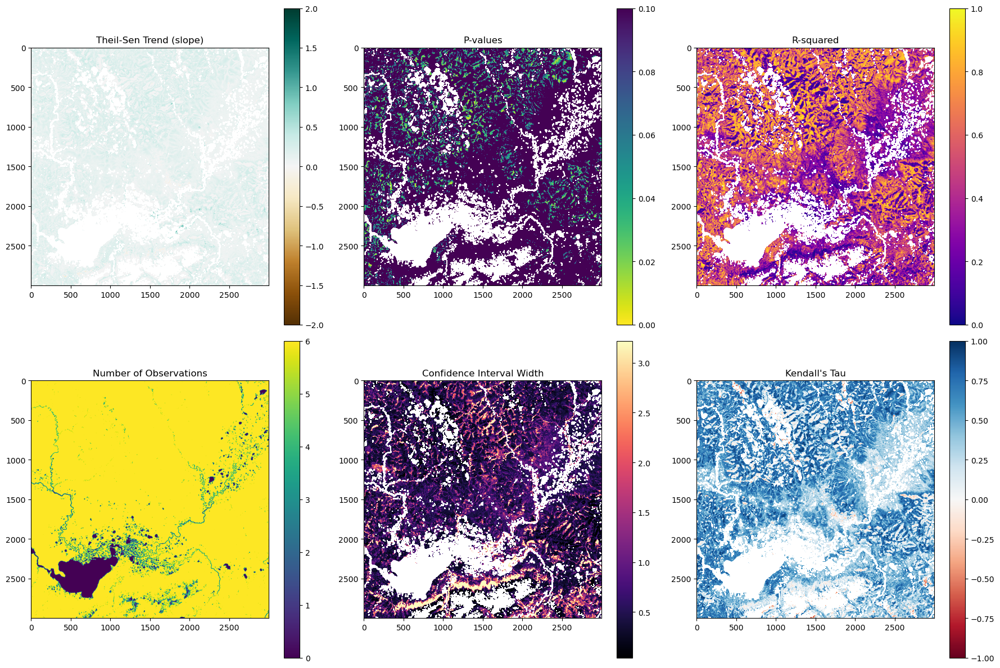

Classifying Kendall's Tau results...
Classified Kendall's Tau raster saved to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_singleyear_atl08v6/boreal_agb_trends_0003638_trend_kendall_tau_classes.tif
  with color table and 10 class definitions
Creating classified map visualization...
Classified map saved to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_singleyear_atl08v6/boreal_agb_trends_0003638_trend_kendall_tau_classified_map.png


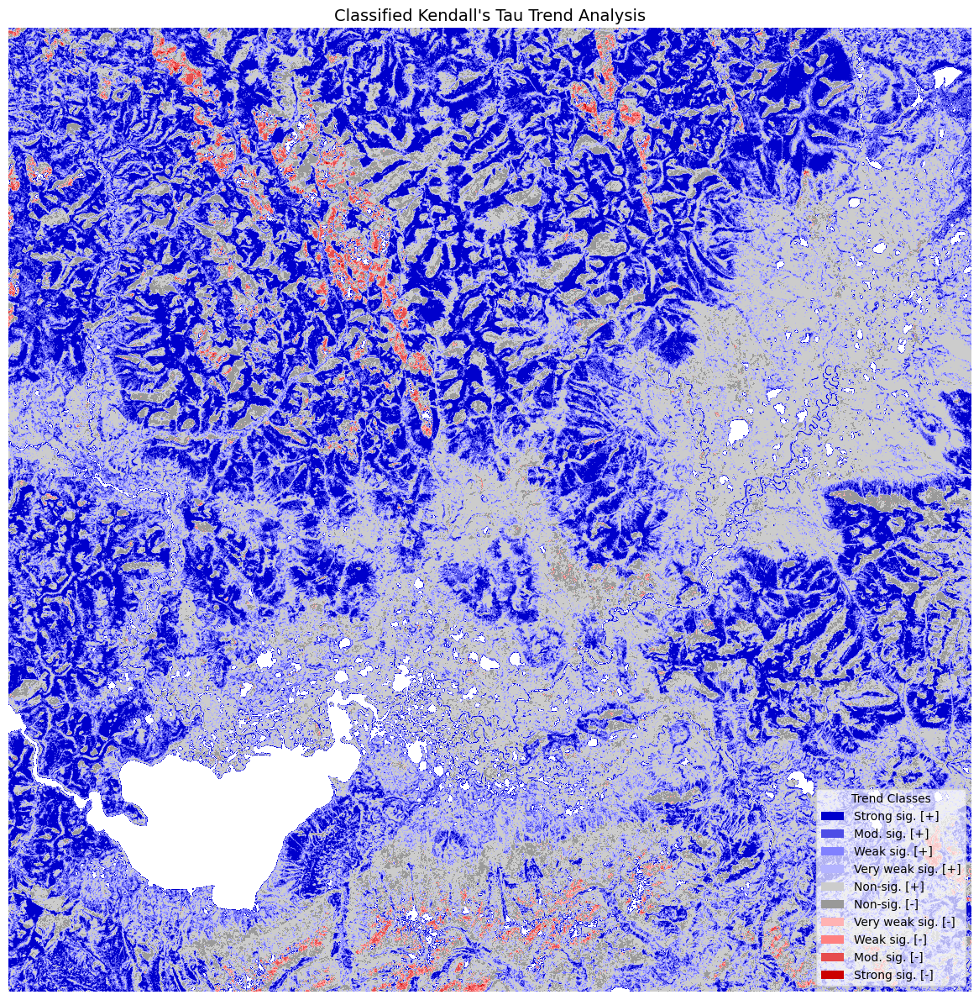

Creating summary statistics visualization...


ValueError: 'label' must be of length 'x'

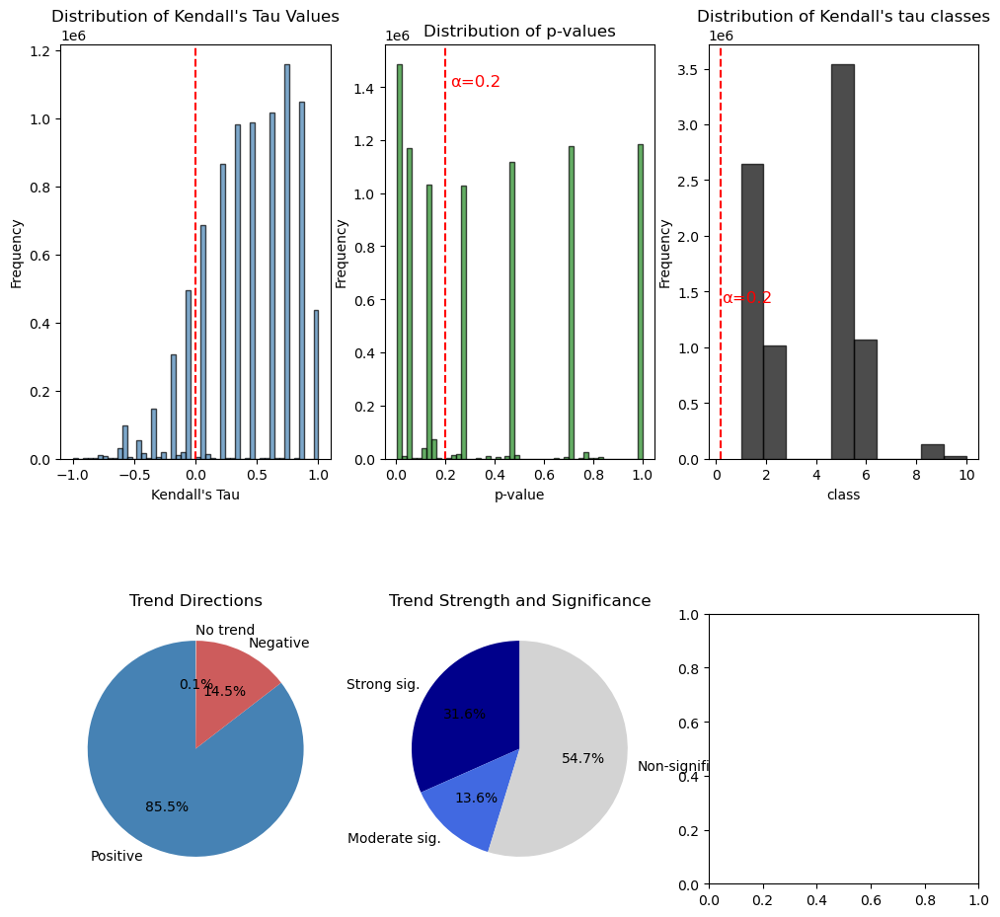

In [148]:
%%time

FOCAL_TILE = 3638
RUN = 'full_run_niter30_singleyear_atl08v6'
YEAR_LIST = list(range(2016,2024+1))

DICT_agbd_singleyear_v6 = {
        'value_raster_files': get_tile_fn_list(
            [f's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_{YEAR}/{RUN}/AGB_tindex_master.csv' \
                                                for RUN in [RUN] for YEAR in YEAR_LIST], 
                                  's3_path', FOCAL_TILE=FOCAL_TILE)[0],
        'outdir': f"{outdir_main}/{RUN}",
        'out_file': f"{outdir_main}/{RUN}/boreal_agb_trends_{FOCAL_TILE:07}_{NUM_YEARS}yrs",
}

wrapper_kendall_tau_analysis(DICT_agbd_singleyear_v6, DATE_RASTER_FILES=fn_list_hls, ALPHA=0.2)

In [127]:
%%time

# Run the analysis
output_arrays, output_files = stack_rasters_and_compute_comprehensive_theilsen(
    value_raster_files=value_raster_files,
    date_raster_files=date_raster_files,
    output_file = OUT_FILE,
    n_processes=30,  # Use 30 CPUs
    chunk_size=300   # Adjust based on memory constraints
)

Using 30 processes for computation
Processing 6 raster pairs...
Raster dimensions: 3000 x 3000
Reading value and date rasters...
  Reading pair 1/6
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2019/mc0_mn50_07-01_08-31_2019_2019/2025/02/13/05/54/01/647431/HLS_475_07-01_08-31_2019_2019.tif
  Reading pair 2/6
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2020/2023/04/11/02/18/31/525544/HLS_475_07-01_08-31_2020_2020.tif
  Reading pair 3/6
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/do_HLS_stack_3-1-2/HLS_stack_2023_v1/HLS_H30_2021/mc25_07-01_08-31_2021_2021/2024/03/17/17/09/52/697112/HLS_475_07-01_08-31_2021_2021.tif
  Reading pair 4/6
Using band 20 for Julian days and band 21 for years in s3://maap-ops-workspace/montesano/dps_output/do_H

Summary plots saved to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_singleyear_atl08v6/boreal_agb_trends_0000475_summary_plots.png


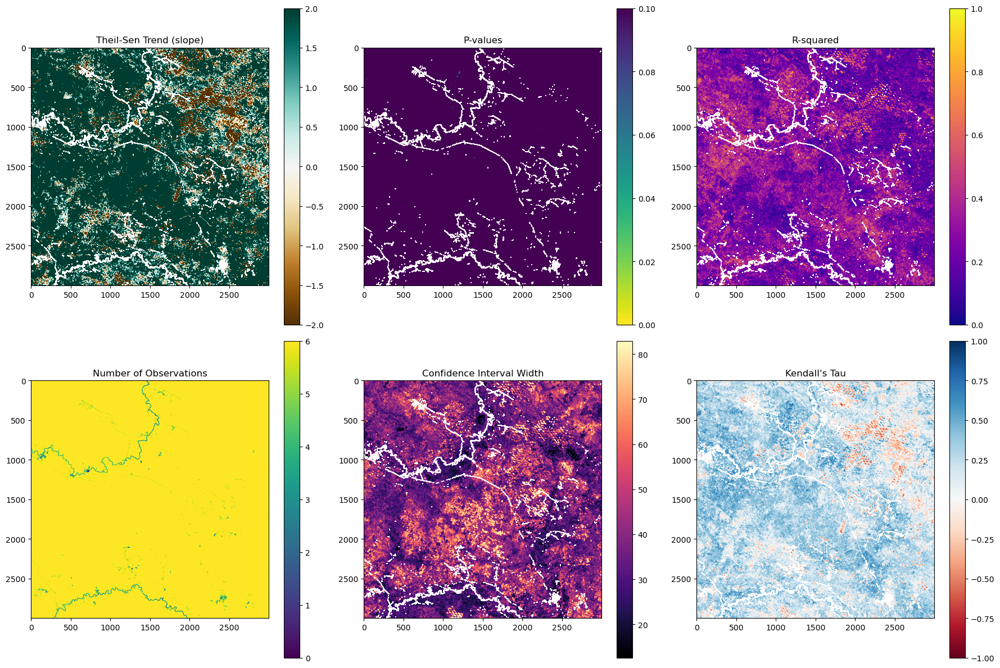

In [128]:
create_summary_plots(output_arrays, OUT_FILE)

In [129]:
# Example usage
n_years = 5  # Your time series length
suggestions = suggest_alpha_by_temporal_resolution(n_years)
print("Suggested alpha thresholds:")
for level, alpha in suggestions.items():
    if level != 'note':
        print(f"  {level.capitalize()}: α = {alpha}")
print(f"Note: {suggestions['note']}")

Suggested alpha thresholds:
  Conservative: α = 0.1
  Standard: α = 0.15
  Liberal: α = 0.2
Note: Few time points - consider more liberal alpha. Consider noise and cloud contamination.


#### Compute Kendall tau from Theil-Sen trends
+ The Kendall tau provides information about the consistency and reliability of that trend

+ Range: Kendall tau values range from -1 to +1

    +1 indicates a perfect positive correlation (consistently increasing trend)  
    -1 indicates a perfect negative correlation (consistently decreasing trend)  
    0 indicates no correlation (no consistent trend)  
+ Statistical Significance: The tau statistic is often accompanied by a p-value that indicates whether the observed trend is statistically significant.

In [130]:
importlib.reload(compute_trends)
from compute_trends import *

In [131]:
# if False:
#     FOCAL_TILE = 518
#     FILE_STEM = f"/projects/my-public-bucket/local_output/compute_trends/boreal_ht_trends_{FOCAL_TILE:07}"
#     # Or load from previously saved files:
#     output_arrays = dict()
#     with rasterio.open(f"{FILE_STEM}_kendall_tau.tif") as src:
#         output_arrays['kendall_tau'] = src.read(1)
#     with rasterio.open(f"{FILE_STEM}_kendall_p.tif") as src:
#         output_arrays['kendall_p'] = src.read(1)

Classifying Kendall's Tau results...
Categorical Kendall's Tau raster saved to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_singleyear_atl08v6/boreal_agb_trends_0000475_trend_kendall_tau_categorical.tif
  with color table and 10 class definitions
Creating classified map visualization...
Classified map saved to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_singleyear_atl08v6/boreal_agb_trends_0000475_trend_kendall_tau_classified_map.png


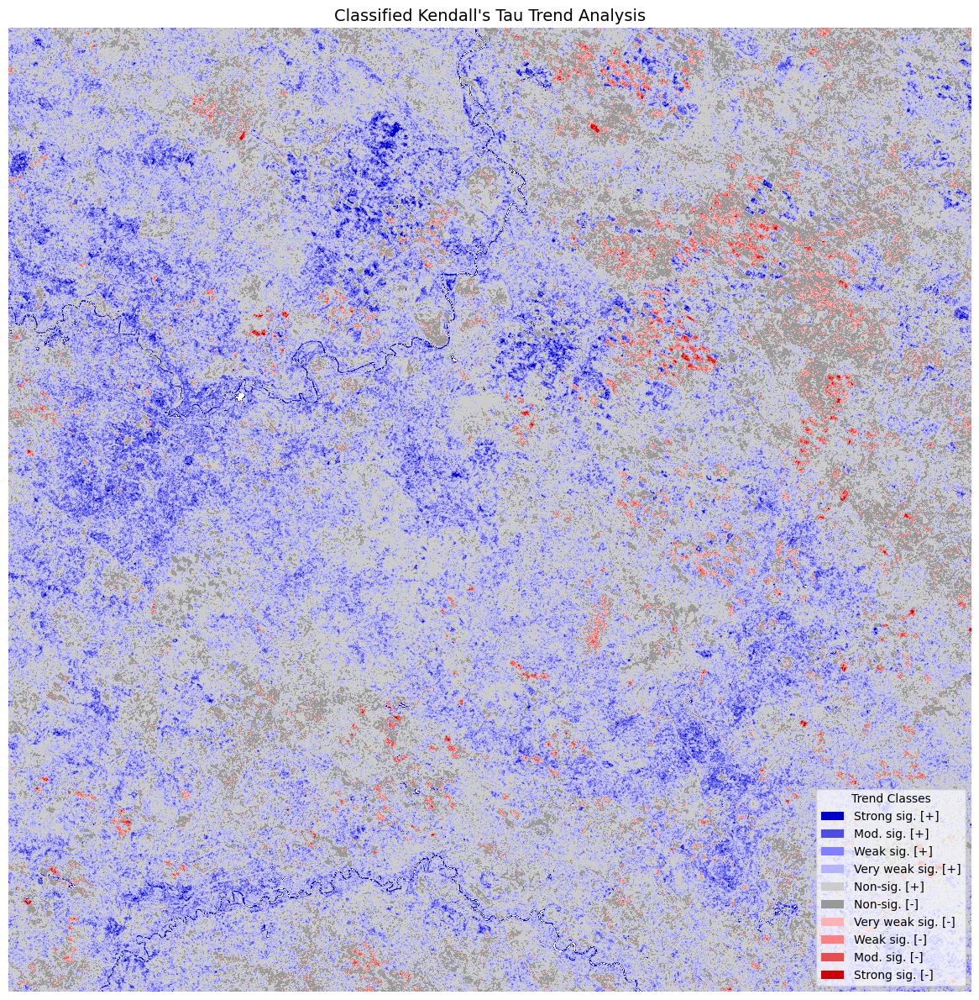

Creating summary statistics visualization...


ValueError: 'label' must be of length 'x'

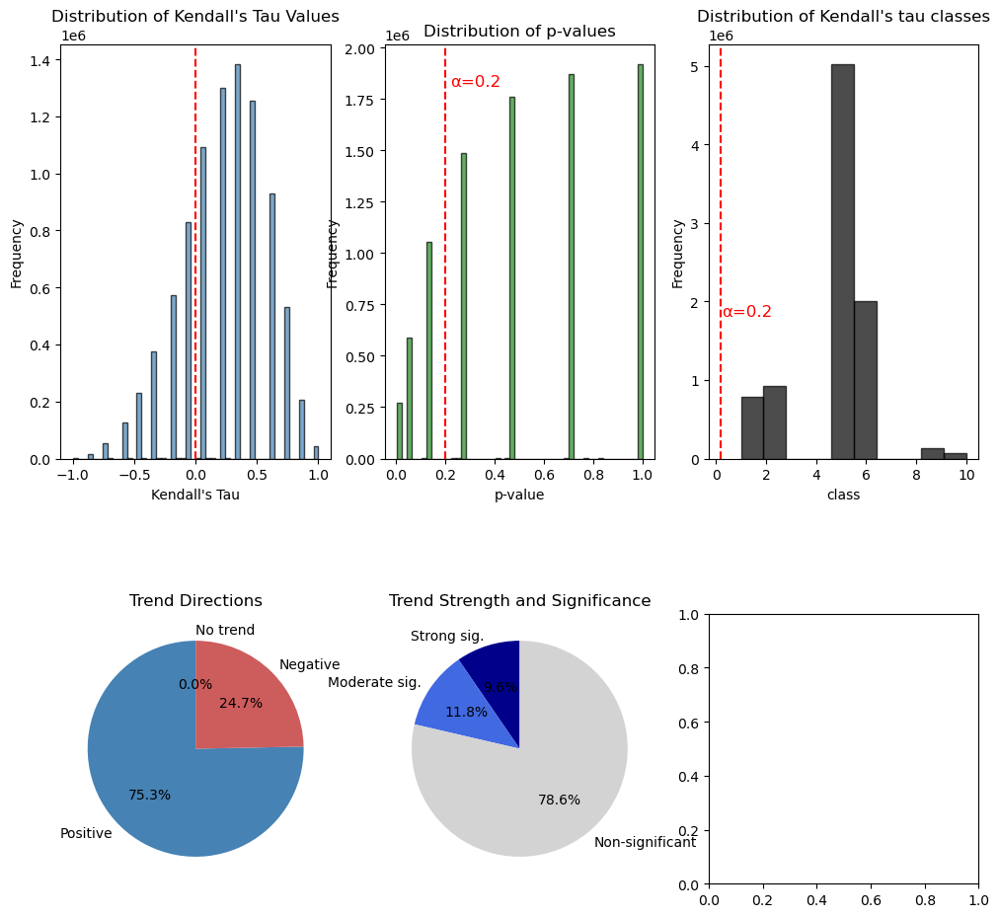

In [132]:
# Example usage in your main analysis pipeline:

# Either use your existing output_arrays from previous analysis:
# tau_array = output_arrays['kendall_tau']
# p_array = output_arrays['kendall_p']
    
# Then run the analysis and visualization
result_paths = analyze_and_visualize_kendall_results(
    output_arrays['kendall_tau'],
    output_arrays['kendall_p'],
    reference_raster_path=f"{OUT_FILE}_trend.tif",
    output_dir=outdir,
    alpha=0.2  # Significance level
)

print("Visualization outputs:")
for name, path in result_paths.items():
    print(f"- {name}: {path}")

While the Theil-Sen estimator provides the magnitude of change (slope)
The Kendall tau provides information about the consistency and reliability of that trend  

Here, we dont care about the consistency of negative trends when considering abrupt negative forest structure change (loss fire, harvest, wind)

In [2]:
# %time
# # Example usage with Bayesian methods

# # Your raster files
# value_raster_files = fn_list_height
# date_raster_files = fn_list_hls

# # Run comprehensive analysis
# output_arrays, output_files = stack_rasters_and_compute_bayesian_theilsen(
#     value_raster_files=value_raster_files,
#     date_raster_files=date_raster_files,
#     output_file="comprehensive_bayesian_theilsen_results",
#     n_processes=20,  # Reduced for Bayesian computation
#     chunk_size=200,  # Smaller chunks for memory management
#     use_bayesian=True,
#     use_robust_bayesian=True
# )